# Merchant onboarding: the recommendation and its limits
**Group 19 · MAST30034 · Non-technical decision summary**

The business can onboard **100 merchants**. Our recommendation is to begin due diligence with the existing **99% “Balanced” global portfolio**: it allows a small reduction in estimated fees to seek steadier weekly income and less dependence on the same customers. The **100% fee-only portfolio** is the transparent alternative when estimated fees take priority.

This notebook explains and displays the saved results. The 99% setting is the dashboard's existing default, **not a newly tuned choice**. All membership, models, segment definitions, weights and existing ranks are preserved. “Expected fees” below are historical, consumer-fraud-adjusted fee estimates in AUD; they are **not net profit, observed fraud losses, or a promise of future returns**.

**Reading route:** recommendation → data quality → method → complete 100-merchant shortlist → ten leaders in each existing segment → supporting evidence → limitations and next steps. Detailed calculations remain in [12_summary.ipynb](12_summary.ipynb).

**Reproduce this view:** run all cells in order using the project Python environment. Only saved CSV/JSON exports and the small merchant/weekly snapshots are read; Spark, source transactions, model fitting and optimisation are unnecessary. New presentation tables are written only to `tables/analysis/submission_summary/`.


In [1]:
from pathlib import Path
import hashlib
import json
import html

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "handoff").is_dir() and (p / "code").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from within the repository.")
DELIVERY = ROOT / "handoff/fraud_adjusted"
FINAL = DELIVERY / "final"
SNAPSHOT = DELIVERY / "input_snapshot"
OUTPUT = ROOT / "tables/analysis/submission_summary"
POLICY = 0.99
FEE = "merchant_expected_monthly_adjusted_fees"
PORTFOLIO_FEE = "portfolio_expected_monthly_adjusted_fees"
SEGMENTS = {
    "tech": "Technology, Digital & Communications",
    "home": "Home, Garden & General Supplies",
    "fashion": "Fashion, Jewellery & Personal Care",
    "arts": "Arts, Crafts, Gifts & Entertainment",
    "auto": "Automotive, Outdoor & Recreational Equipment",
}
FILES = {"global": "portfolio_dashboard.csv", **{
    scope: f"{scope}_portfolio_dashboard.csv" for scope in SEGMENTS}}
source_hashes = {}

def checked_hash(path, expected=None):
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if expected is not None and digest != expected:
        raise ValueError(f"Saved source does not match its manifest: {path}")
    source_hashes[str(path.relative_to(ROOT))] = digest
    return digest

def read_json(path):
    checked_hash(path)
    return json.loads(path.read_text())

def show_table(frame, formats=None):
    # Render every supplied row, rather than pandas' truncated head/tail view.
    display(HTML(frame.to_html(index=False, escape=True, border=0,
                              max_rows=None, formatters=formats or {},
                              classes="summary-table")))

manifest = read_json(FINAL / "manifest.json")
snapshot_meta = read_json(SNAPSHOT / "snapshot.json")
preparation = read_json(DELIVERY / "provenance/preparation_complete.json")
if snapshot_meta.get("fee_basis") != "consumer_fraud_adjusted":
    raise ValueError("The summary requires the matching fraud-adjusted snapshot.")

saved = {}
for scope, filename in FILES.items():
    path = FINAL / filename
    checked_hash(path, manifest["files"][filename])
    frame = pd.read_csv(path, dtype={"merchant_abn": "string"})
    if set(frame["fee_basis"]) != {"consumer_fraud_adjusted"} or set(frame["scope"]) != {scope}:
        raise ValueError(f"Unexpected scope or fee basis: {filename}")
    saved[scope] = frame

for filename, key in [("merchants.parquet", "merchants"), ("weekly_fees.parquet", "weekly_fees")]:
    checked_hash(SNAPSHOT / filename, snapshot_meta["sha256"][key])
merchants = pd.read_parquet(SNAPSHOT / "merchants.parquet")
merchants["merchant_abn"] = merchants["merchant_abn"].astype("string")
weekly = pd.read_parquet(SNAPSHOT / "weekly_fees.parquet")
weekly["merchant_abn"] = weekly["merchant_abn"].astype("string")
if not merchants["merchant_abn"].is_unique:
    raise ValueError("Merchant master contains duplicate identifiers.")

portfolio_fields = [
    "scope", "retention", "as_of", "currency", "window_start", "window_end",
    "portfolio_size", "variability_weight", "concentration_weight", PORTFOLIO_FEE,
    "portfolio_variability_cv", "portfolio_customer_hhi", "portfolio_risk_score",
    "portfolio_expected_fee_retention", "portfolio_certified", "portfolio_optimality_gap",
    "portfolio_status",
]
all_saved = pd.concat(saved.values(), ignore_index=True)
for portfolio_id, group in all_saved.groupby("portfolio_id"):
    if len(group) != 100 or group["merchant_abn"].nunique() != 100:
        raise ValueError(f"Expected 100 distinct saved merchants: {portfolio_id}")
    if sorted(group["rank_by_expected_fees"]) != list(range(1, 101)):
        raise ValueError(f"Missing or repeated existing ranks: {portfolio_id}")
    if (group[portfolio_fields].nunique(dropna=False) != 1).any():
        raise ValueError(f"Inconsistent repeated portfolio metrics: {portfolio_id}")
    if not np.isclose(group[FEE].sum(), group[PORTFOLIO_FEE].iloc[0], rtol=1e-10):
        raise ValueError(f"Merchant fees do not reconcile: {portfolio_id}")
    check = group.merge(merchants[["merchant_abn", "expected_monthly_fees", "eligible"]],
                        on="merchant_abn", how="left", validate="many_to_one")
    if not check["eligible"].eq(True).all() or not np.allclose(
            check[FEE], check["expected_monthly_fees"], rtol=1e-10):
        raise ValueError(f"Portfolio does not match its frozen merchant snapshot: {portfolio_id}")
for field, value in [("as_of", snapshot_meta["as_of"]),
                     ("window_start", snapshot_meta["window_start"]),
                     ("window_end", snapshot_meta["window_end"]), ("currency", "AUD")]:
    if set(all_saved[field]) != {value}:
        raise ValueError(f"Mixed snapshot definitions: {field}")
if not (all_saved["variability_weight"].eq(0.5).all()
        and all_saved["concentration_weight"].eq(0.5).all()):
    raise ValueError("This narrative describes the existing 50/50 risk weights.")

# Recover the existing category allocation from saved scope membership.
# Reject ambiguity or incomplete coverage; do not invent a new segment rule.
category_scope = pd.concat([
    frame[["merchant_category"]].drop_duplicates().assign(segment_scope=scope)
    for scope, frame in saved.items() if scope != "global"
]).drop_duplicates()
if category_scope["merchant_category"].duplicated().any():
    raise ValueError("A source category occurs in more than one saved segment.")
category_to_scope = category_scope.set_index("merchant_category")["segment_scope"]
merchants["segment_scope"] = merchants["category"].map(category_to_scope)
if merchants["segment_scope"].isna().any():
    raise ValueError("The saved segment exports do not document every master category.")
merchants["segment"] = merchants["segment_scope"].map(SEGMENTS)

metrics = all_saved[["portfolio_id", *portfolio_fields]].drop_duplicates("portfolio_id")
global_metrics = metrics.loc[metrics["scope"].eq("global")].sort_values("retention", ascending=False)

def portfolio(scope, retention):
    rows = saved[scope].loc[np.isclose(saved[scope]["retention"], retention)].copy()
    if len(rows) != 100 or rows["portfolio_id"].nunique() != 1:
        raise ValueError(f"Missing unique saved selection: {scope}, {retention}")
    return rows.sort_values("rank_by_expected_fees")

chosen = portfolio("global", POLICY)
baseline = portfolio("global", 1.0)
chosen_metric, baseline_metric = chosen.iloc[0], baseline.iloc[0]
selected_ids = set(chosen["merchant_abn"])
baseline_ids = set(baseline["merchant_abn"])
merchants["selected_global_99"] = merchants["merchant_abn"].isin(selected_ids)

plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
display(HTML("<style>.summary-table {font-size: 13px; border-collapse: collapse;} "
             ".summary-table th,.summary-table td {padding: 7px 10px; text-align: left; "
             "border-bottom: 1px solid #ddd;} .summary-table th {background: #edf3f5;}</style>"))
display(Markdown(f"**Saved decision date:** {snapshot_meta['as_of']} · "
                 f"**Merchant master:** {len(merchants):,} · "
                 f"**Eligible:** {int(merchants['eligible'].sum()):,} · "
                 f"**Saved portfolios checked:** {len(metrics)}. No models were rerun."))


**Saved decision date:** 2022-09-30 · **Merchant master:** 4,026 · **Eligible:** 3,897 · **Saved portfolios checked:** 30. No models were rerun.

## 1. The decision in plain language

The 99% policy preserves at least 99% of the fee-only portfolio's estimated fees. It then seeks a better combination of weekly stability and customer diversification. The table reports **whole-portfolio** amounts once, rather than adding values repeated on every merchant row.

A lower combined risk index is better **within this scope and snapshot**. It is not the chance of default, and an improvement of one index point is not one percentage point less fraud. Numerical certification concerns the search's optimisation tolerance; it does not certify future business performance.


Policy,Monthly adjusted fees (AUD),Fee retention achieved,Weekly variability (CV),Customer concentration (HHI),Combined risk index,Solver tolerance met,Optimisation gap
100% · fee-only baseline,"$1,551,710",100.000%,3.138%,0.00004583,100.000,Yes,0.000%
99% · existing Balanced policy,"$1,536,393",99.013%,3.088%,0.00004527,98.601,Yes,0.048%


**Trade-off:** the saved Balanced selection estimates **A$1,536,393 per month**, A$15,317 below the fee-only baseline. It replaces **4 of 100 merchants**. Historical weekly variability is 1.57% lower and customer concentration is 1.23% lower, giving a **1.399-point** improvement in the combined index. These are modest modelled improvements to weigh against the foregone fee estimate, not measured savings or losses.

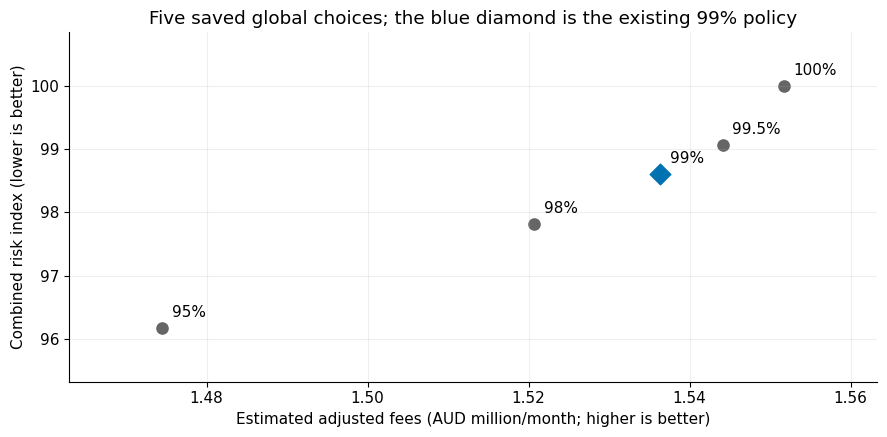

In [2]:
comparison = pd.DataFrame([
    {"Policy": label,
     "Monthly adjusted fees (AUD)": row[PORTFOLIO_FEE],
     "Fee retention achieved": row["portfolio_expected_fee_retention"],
     "Weekly variability (CV)": row["portfolio_variability_cv"],
     "Customer concentration (HHI)": row["portfolio_customer_hhi"],
     "Combined risk index": row["portfolio_risk_score"],
     "Solver tolerance met": "Yes" if bool(row["portfolio_certified"]) else "No",
     "Optimisation gap": row["portfolio_optimality_gap"]}
    for label, row in [("100% · fee-only baseline", baseline_metric),
                       ("99% · existing Balanced policy", chosen_metric)]
])
show_table(comparison, {
    "Monthly adjusted fees (AUD)": "${:,.0f}".format,
    "Fee retention achieved": "{:.3%}".format,
    "Weekly variability (CV)": "{:.3%}".format,
    "Customer concentration (HHI)": "{:.8f}".format,
    "Combined risk index": "{:.3f}".format,
    "Optimisation gap": "{:.3%}".format,
})
fee_difference = baseline_metric[PORTFOLIO_FEE] - chosen_metric[PORTFOLIO_FEE]
risk_points = baseline_metric["portfolio_risk_score"] - chosen_metric["portfolio_risk_score"]
cv_change = 1 - chosen_metric["portfolio_variability_cv"] / baseline_metric["portfolio_variability_cv"]
hhi_change = 1 - chosen_metric["portfolio_customer_hhi"] / baseline_metric["portfolio_customer_hhi"]
display(Markdown(
    f"**Trade-off:** the saved Balanced selection estimates **A${chosen_metric[PORTFOLIO_FEE]:,.0f} "
    f"per month**, A${fee_difference:,.0f} below the fee-only baseline. It replaces "
    f"**{len(selected_ids - baseline_ids)} of 100 merchants**. Historical weekly variability "
    f"is {cv_change:.2%} lower and customer concentration is {hhi_change:.2%} lower, giving "
    f"a **{risk_points:.3f}-point** improvement in the combined index. "
    "These are modest modelled improvements to weigh against the foregone fee estimate, "
    "not measured savings or losses."
))
fig, ax = plt.subplots(figsize=(9, 4.5))
for _, row in global_metrics.iterrows():
    active = np.isclose(row["retention"], POLICY)
    ax.scatter(row[PORTFOLIO_FEE] / 1e6, row["portfolio_risk_score"],
               s=110 if active else 65, color="#0072B2" if active else "#666666",
               marker="D" if active else "o")
    ax.annotate(f"{row['retention']:.1%}".replace(".0%", "%"),
                (row[PORTFOLIO_FEE] / 1e6, row["portfolio_risk_score"]),
                xytext=(7, 8), textcoords="offset points")
ax.set(xlabel="Estimated adjusted fees (AUD million/month; higher is better)",
       ylabel="Combined risk index (lower is better)",
       title="Five saved global choices; the blue diamond is the existing 99% policy")
ax.grid(alpha=0.2)
ax.margins(x=0.15, y=0.22)
fig.tight_layout()
plt.show()
plt.close(fig)


The chart shows the five saved choices, not an exhaustive or newly optimised frontier. If the business puts less value on stability and diversification, the 100% baseline remains a defensible alternative. There is no evidence here that 99% is uniquely best for every firm's costs or risk appetite.

## 2. What data support the decision?

The supplied data describe synthetic merchants, customers, user/customer links, transactions and sparse entity/date fraud scores. The final fee estimate averages **19 complete months, March 2021–September 2022**; risk uses **26 complete weeks, 28 March–25 September 2022**. The frozen snapshot records the 30 September 2022 decision cutoff.

External **2021 ABS SA2 personal income** is joined through mesh-block population weights to state/postcode areas. This provides geographic context for customers; it is an average of area medians, **not an individual's income or the postcode median**. Income does not enter the saved portfolio objective. External-data exploration remains in [00_preliminary_analysis](00_preliminary_analysis.ipynb), [01_etl](01_etl.ipynb), [02_analysis](02_analysis.ipynb) and [03_external_data_comparison](03_external_data_comparison.ipynb).

### Missing data, joins and unusual observations

| Issue | Existing treatment and its implication |
|---|---|
| User/customer joins | Unique-key checks and left joins preserve orders. The full ETL's saved audit reports no missing consumer details. |
| Missing ABS income | The full ETL records **2,368,565 of 14,195,505 orders** without an income match. It fills these with the approximate median of available transaction-level income and retains `income_matched`. These are recorded ETL audit counts, not a new transaction scan. |
| Sparse fraud scores | Preserve supplied scores; estimate missing consumer/date scores using the existing regression. Imputation does not turn estimates into verified outcomes. The final-run counts below use its own complete-history denominator. |
| Missing merchant records | Retain transactions in the audit, but do not invent take rates. Orders without merchant metadata are outside fee-based selection. |
| No prior spending history | The completed ETL export uses a flagged median fallback. The model's same-day consumer features and historical revenue estimates remain retrospective. |
| Outliers | The existing analysis counts **46,192 transaction-value** and **3,548 district-income** outliers using its stated z-score threshold (5.7391). Transactions are retained: an unusual high-value purchase is not automatically an error or fraud. No before/after deletion claim is made. Income flags describe the already-imputed distribution. |

The quoted full-ETL counts cover a broader stored history than the final 19-month preparation. They must **not** be mixed as if their denominators were identical. See the saved [ETL audit](01_etl.ipynb) and [distribution analysis](02_analysis.ipynb) for the original outputs. Retention preserves potentially useful large purchases, but does not establish that every extreme value is genuine; individual review remains necessary.


In [3]:
rows = int(preparation["rows"])
quality = pd.DataFrame([
    ("Transactions in final complete-history preparation", rows, "All processed orders"),
    ("Orders with merchant metadata", int(preparation["known_orders"]), "Eligible for fee calculation; further merchant rules still apply"),
    ("Orders without merchant metadata", int(preparation["unknown_merchant_orders"]), "Excluded from fee-based selection; no invented take rate"),
    ("Orders retaining a supplied consumer score", int(preparation["observed_orders"]), "Observed score, not verified transaction outcome"),
    ("Orders using an estimated consumer score", int(preparation["imputed_orders"]), "Existing retrospective OLS; supplied values preserved"),
    ("Orders flagged outside labelled predictor support", int(preparation["low_support_orders"]), "Model support warning, not a confirmed-fraud label"),
    ("Orders still missing a completed consumer score", int(preparation["missing_scores"]), "Completeness does not imply accuracy"),
], columns=["Recorded final-run check", "Orders", "Meaning"])
quality["Share of preparation"] = quality["Orders"] / rows
show_table(quality[["Recorded final-run check", "Orders", "Share of preparation", "Meaning"]],
           {"Orders": "{:,.0f}".format, "Share of preparation": "{:.2%}".format})
display(Markdown(
    f"**Main evidence limitation:** {preparation['low_support_orders'] / rows:.2%} of orders "
    "carry the model's low-support flag. Sparse observed labels cannot validate estimated "
    "fraud risk throughout this much larger population. Rows in this table overlap: "
    "low-support orders are not an additional population to add to imputed orders."
))


Recorded final-run check,Orders,Share of preparation,Meaning
Transactions in final complete-history preparation,"13,440,766",100.00%,All processed orders
Orders with merchant metadata,"12,890,819",95.91%,Eligible for fee calculation; further merchant rules still apply
Orders without merchant metadata,"549,947",4.09%,Excluded from fee-based selection; no invented take rate
Orders retaining a supplied consumer score,"80,308",0.60%,"Observed score, not verified transaction outcome"
Orders using an estimated consumer score,"13,360,458",99.40%,Existing retrospective OLS; supplied values preserved
Orders flagged outside labelled predictor support,"12,951,733",96.36%,"Model support warning, not a confirmed-fraud label"
Orders still missing a completed consumer score,0,0.00%,Completeness does not imply accuracy


**Main evidence limitation:** 96.36% of orders carry the model's low-support flag. Sparse observed labels cannot validate estimated fraud risk throughout this much larger population. Rows in this table overlap: low-support orders are not an additional population to add to imputed orders.

## 3. How the existing method works

1. **Prepare comparable data.** Automate ingestion, validate join keys, preserve row counts, attach external context and record missingness. Use the existing eligibility rules; insufficient-history merchants stay visible but outside the selection pool.
2. **Estimate the fees a merchant could contribute.** For each transaction, multiply sales by the merchant take rate and by `(1 − consumer fraud score / 100)`. Average the monthly totals across the same 19 months, including genuine zero months. This is a fee-earning proxy; the merchant fraud score is not multiplied in again.
3. **Evaluate merchants together.** Weekly variability measures how much total fees fluctuate relative to their mean. Customer concentration measures reliance on the same customers across merchants. Both are evaluated for the whole portfolio: a merchant's contribution depends on its companions.
4. **Choose 100 under the existing fee floor.** The existing optimiser combines baseline-relative variability and concentration with **50/50 weights**, subject to the selected return-retention floor. Each segment uses its own candidate pool and fee-only baseline. The five existing segment definitions are unchanged.
5. **Order the saved selection for display.** Within each selected portfolio, the existing rank sorts by estimated adjusted monthly fees. This is a revenue display order, **not an independent merchant risk score**.

This notebook performs none of those optimisation or training steps again. [12_summary](12_summary.ipynb) contains formulas; [04_cash_flow_variability](04_cash_flow_variability.ipynb), [09_customer_concentration](09_customer_concentration.ipynb) and [10_categories](10_categories.ipynb) explain the supporting analysis.

## 4. The complete 100-merchant recommendation

The following table includes **all 100 saved members** of the existing global 99% portfolio. The rank, membership and fee estimates come directly from the final export. The segment is the existing classification recovered from the five saved segment exports.


Existing rank,ABN,Merchant,Existing segment,Category,Adjusted fees (AUD/month)
1,32361057556,Orci In Consequat Corporation,"Arts, Crafts, Gifts & Entertainment","gift, card, novelty, and souvenir shops","$29,658.60"
2,48534649627,Dignissim Maecenas Foundation,"Fashion, Jewellery & Personal Care","opticians, optical goods, and eyeglasses","$29,586.59"
3,79827781481,Amet Risus Inc.,"Home, Garden & General Supplies","furniture, home furnishings and equipment shops, and manufacturers, except appliances","$29,337.70"
4,86578477987,Leo In Consulting,"Fashion, Jewellery & Personal Care","watch, clock, and jewelry repair shops","$29,283.46"
5,45629217853,Lacus Consulting,"Arts, Crafts, Gifts & Entertainment","gift, card, novelty, and souvenir shops","$27,975.32"
6,38700038932,Etiam Bibendum Industries,"Automotive, Outdoor & Recreational Equipment",tent and awning shops,"$27,546.71"
7,21439773999,Mauris Non Institute,"Technology, Digital & Communications","cable, satellite, and other pay television and radio services","$27,370.21"
8,96680767841,Ornare Limited,"Automotive, Outdoor & Recreational Equipment",motor vehicle supplies and new parts,"$27,364.49"
9,64403598239,Lobortis Ultrices Company,"Arts, Crafts, Gifts & Entertainment","music shops - musical instruments, pianos, and sheet music","$26,659.87"
10,63123845164,Odio Phasellus Institute,"Arts, Crafts, Gifts & Entertainment",artist supply and craft shops,"$26,313.52"


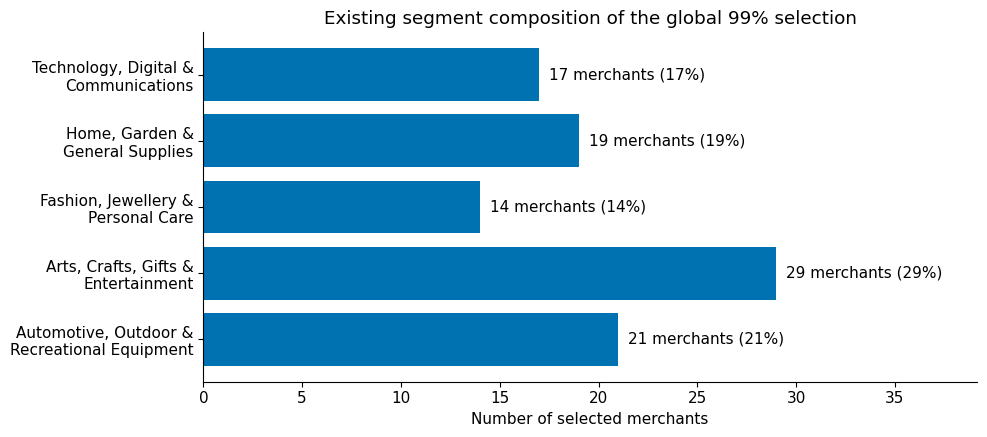

In [4]:
recommendation = chosen[["rank_by_expected_fees", "merchant_abn", "merchant_name",
                         "merchant_category", FEE]].merge(
    merchants[["merchant_abn", "segment"]], on="merchant_abn", how="left", validate="one_to_one"
).sort_values("rank_by_expected_fees")
recommendation = recommendation.rename(columns={
    "rank_by_expected_fees": "Existing rank", "merchant_abn": "ABN",
    "merchant_name": "Merchant", "merchant_category": "Category",
    "segment": "Existing segment", FEE: "Adjusted fees (AUD/month)",
})
recommendation = recommendation[["Existing rank", "ABN", "Merchant", "Existing segment",
                                 "Category", "Adjusted fees (AUD/month)"]]
if len(recommendation) != 100:
    raise AssertionError("The complete recommendation must contain 100 rows.")
show_table(recommendation, {"Adjusted fees (AUD/month)": "${:,.2f}".format})

composition = recommendation["Existing segment"].value_counts().reindex(SEGMENTS.values(), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [label.replace(" & ", " &\n") for label in composition.index]
ax.barh(labels, composition.values, color="#0072B2")
for index, value in enumerate(composition.values):
    ax.text(value + 0.5, index, f"{value} merchants ({value / len(recommendation):.0%})", va="center")
ax.set(xlabel="Number of selected merchants", title="Existing segment composition of the global 99% selection")
ax.set_xlim(0, max(composition.max() * 1.35, 10))
ax.invert_yaxis()
fig.tight_layout()
plt.show()
plt.close(fig)


## 5. Ten leaders in each of the five existing segments

Each segment currently has its own **100-member** portfolio. The tables below show **existing ranks 1–10 inside that segment's saved 99% portfolio**. They are a ranked subset of that selection, **not a newly optimised ten-merchant portfolio**. Their risk, retention and optimality cannot be inferred from the corresponding 100-member portfolio.

These are segment-specific views, not 50 extra onboarding recommendations to append to the global 100. They can overlap with the global selection. Scope-relative risk indices should not be compared across segments as if they shared one absolute risk scale.


In [5]:
segment_tables = []
segment_status = []
for scope, label in SEGMENTS.items():
    segment_portfolio = portfolio(scope, POLICY)
    row = segment_portfolio.iloc[0]
    segment_status.append({
        "Existing segment": label,
        "100-member search status": str(row["portfolio_status"]),
        "Solver tolerance met": "Yes" if bool(row["portfolio_certified"]) else "No",
        "Optimisation gap": row["portfolio_optimality_gap"],
    })
    top = segment_portfolio.loc[segment_portfolio["rank_by_expected_fees"].le(10),
                                ["rank_by_expected_fees", "merchant_abn", "merchant_name", FEE]].copy()
    if len(top) != 10:
        raise AssertionError(f"Expected ten existing segment ranks for {scope}.")
    top["Also in global 99%"] = np.where(top["merchant_abn"].isin(selected_ids), "Yes", "No")
    top = top.rename(columns={"rank_by_expected_fees": "Existing segment rank", "merchant_abn": "ABN",
                              "merchant_name": "Merchant", FEE: "Adjusted fees (AUD/month)"})
    display(Markdown(f"### {label}"))
    show_table(top, {"Adjusted fees (AUD/month)": "${:,.2f}".format})
    segment_tables.append(top.assign(**{"Existing segment": label}))
segment_top10 = pd.concat(segment_tables, ignore_index=True)
display(Markdown("**Search evidence for the parent 100-member portfolios** — not certification of these ten-member subsets:"))
show_table(pd.DataFrame(segment_status), {"Optimisation gap": "{:.3%}".format})


### Technology, Digital & Communications

Existing segment rank,ABN,Merchant,Adjusted fees (AUD/month),Also in global 99%
1,21439773999,Mauris Non Institute,"$27,370.21",Yes
2,82368304209,Nec Incorporated,"$23,689.83",Yes
3,35909341340,Arcu Sed Eu Incorporated,"$21,620.41",Yes
4,72472909171,Nullam Consulting,"$21,576.43",Yes
5,45433476494,Adipiscing Elit Foundation,"$19,648.43",Yes
6,58454491168,Diam At Foundation,"$19,063.36",Yes
7,94690988633,Eu Placerat LLC,"$18,445.68",Yes
8,49505931725,Suspendisse Ac Associates,"$16,069.32",Yes
9,67400260923,Eleifend PC,"$15,933.90",Yes
10,80518954462,Neque Sed Dictum Incorporated,"$14,699.23",Yes


### Home, Garden & General Supplies

Existing segment rank,ABN,Merchant,Adjusted fees (AUD/month),Also in global 99%
1,79827781481,Amet Risus Inc.,"$29,337.70",Yes
2,76767266140,Phasellus At Limited,"$20,590.48",Yes
3,43186523025,Lorem Ipsum Sodales Industries,"$19,281.53",Yes
4,49212265466,Auctor Company,"$17,303.39",Yes
5,57757792876,Pretium Et LLC,"$16,382.20",Yes
6,21772962346,Purus Gravida Sagittis Ltd,"$16,237.20",Yes
7,42355028515,Eu Inc.,"$15,579.22",Yes
8,76314317957,Semper Corp.,"$13,982.69",Yes
9,38090089066,Interdum Feugiat Sed Inc.,"$13,686.51",Yes
10,32709545238,Tempor Est Foundation,"$13,672.85",Yes


### Fashion, Jewellery & Personal Care

...

Existing segment rank,ABN,Merchant,Adjusted fees (AUD/month),Also in global 99%
1,32361057556,Orci In Consequat Corporation,"$29,658.60",Yes
2,45629217853,Lacus Consulting,"$27,975.32",Yes
3,64403598239,Lobortis Ultrices Company,"$26,659.87",Yes
4,63123845164,Odio Phasellus Institute,"$26,313.52",Yes
5,94493496784,Dictum Phasellus In Institute,"$24,514.67",Yes
6,79417999332,Phasellus At Company,"$21,515.15",Yes
7,40515428545,Elit Sed Consequat Associates,"$21,427.13",Yes
8,67978471888,Magna Malesuada Corp.,"$21,031.95",Yes
9,98166254020,Magna Sed Industries,"$19,548.49",Yes
10,98973094975,Ornare Fusce Inc.,"$19,406.48",Yes


### Automotive, Outdoor & Recreational Equipment

Existing segment rank,ABN,Merchant,Adjusted fees (AUD/month),Also in global 99%
1,38700038932,Etiam Bibendum Industries,"$27,546.71",Yes
2,96680767841,Ornare Limited,"$27,364.49",Yes
3,89726005175,Est Nunc Consulting,"$25,508.23",Yes
4,49891706470,Non Vestibulum Industries,"$19,834.21",Yes
5,80551528183,Ac Ipsum LLC,"$19,554.97",Yes
6,90568944804,Diam Eu Dolor LLC,"$18,257.68",Yes
7,13514558491,Magna Praesent PC,"$18,080.99",Yes
8,75454398468,Tempus Non Lacinia Corporation,"$18,023.42",Yes
9,49549583265,Luctus Et Incorporated,"$17,953.88",Yes
10,31385641294,Semper Auctor PC,"$16,243.90",Yes


**Search evidence for the parent 100-member portfolios** — not certification of these ten-member subsets:

Existing segment,100-member search status,Solver tolerance met,Optimisation gap
"Technology, Digital & Communications",certified_gap,Yes,0.089%
"Home, Garden & General Supplies",bounded_best_found_stagnation,No,1.008%
"Fashion, Jewellery & Personal Care",certified_gap,Yes,0.088%
"Arts, Crafts, Gifts & Entertainment",bounded_best_found_stagnation,No,0.377%
"Automotive, Outdoor & Recreational Equipment",certified_gap,Yes,0.098%


## 6. What distinguishes selected and unselected merchants?

The comparison below uses only the matching frozen merchant and weekly snapshots. “Not selected” does not mean “bad merchant”: the business has 100 places, and the optimisation evaluates combinations under a fee floor.

The individual weekly variability shown here is ordinary sample standard deviation divided by mean weekly fees, including all 26 weeks. It is a descriptive merchant measure, **not the model's shrunk whole-portfolio variability**, and is not used here to rerank or select anyone. Median comparisons describe associations; they do not establish why any particular merchant was selected.


In [6]:
if weekly.duplicated(["merchant_abn", "week_end"]).any():
    raise ValueError("Duplicate merchant/week entries in the frozen snapshot.")
week_counts = weekly.groupby("merchant_abn").size()
if not week_counts.eq(snapshot_meta["weeks"]).all():
    raise ValueError("Individual comparisons require the complete common weekly history.")
# The snapshot's legacy gross_fees field contains ADJUSTED fees, per snapshot metadata.
weekly_stats = weekly.groupby("merchant_abn")["gross_fees"].agg(["mean", "std"])
weekly_stats["individual_weekly_cv"] = weekly_stats["std"].div(weekly_stats["mean"].where(weekly_stats["mean"].gt(0)))
evidence = merchants.merge(weekly_stats[["individual_weekly_cv"]], left_on="merchant_abn",
                           right_index=True, how="left", validate="one_to_one")
evidence["group"] = np.select(
    [~evidence["eligible"], evidence["selected_global_99"]],
    ["Ineligible under existing rules", "Selected: global 99%"],
    default="Eligible, not selected at 99%",
)
group_summary = evidence.groupby("group").agg(
    merchants=("merchant_abn", "size"),
    median_adjusted_monthly_fees=("expected_monthly_fees", "median"),
    median_individual_weekly_cv=("individual_weekly_cv", "median"),
).reindex(["Selected: global 99%", "Eligible, not selected at 99%", "Ineligible under existing rules"])
group_summary = group_summary.reset_index().rename(columns={
    "group": "Group", "merchants": "Merchants",
    "median_adjusted_monthly_fees": "Median adjusted fees (AUD/month)",
    "median_individual_weekly_cv": "Median individual weekly variability",
})
show_table(group_summary, {"Median adjusted fees (AUD/month)": "${:,.2f}".format,
                           "Median individual weekly variability": "{:.2%}".format})
eligibility = merchants.loc[~merchants["eligible"], "eligibility_reason"].value_counts().rename_axis(
    "Existing exclusion reason").reset_index(name="Merchants")
show_table(eligibility)


Group,Merchants,Median adjusted fees (AUD/month),Median individual weekly variability
Selected: global 99%,100,"$13,821.41",9.81%
"Eligible, not selected at 99%",3797,$240.35,53.60%
Ineligible under existing rules,129,$38.71,427.32%


Existing exclusion reason,Merchants
no_previous_sales,87
no_recent_sales,42


### Interesting merchants and the actual substitutions

These examples come from the existing results: the largest fee contributor in the recommended portfolio, the highest-fee eligible merchant it does not select, and every merchant exchanged between the 100% and 99% portfolios. Together they show why the recommendation is more than simply taking the largest individual fee estimates.

The comparison does **not** assign the change in portfolio risk to an individual merchant. Covariance between merchants and shared customers are joint properties. Review the transaction history and merchant context before using any example as an onboarding decision.


In [7]:
lookup = evidence.set_index("merchant_abn")
examples = []

def add_example(abn, role):
    row = lookup.loc[abn]
    examples.append({"Role in the comparison": role, "ABN": abn, "Merchant": row["name"],
                     "Existing segment": row["segment"],
                     "Adjusted fees (AUD/month)": row["expected_monthly_fees"],
                     "Individual weekly variability": row["individual_weekly_cv"]})

add_example(chosen.iloc[0]["merchant_abn"], "Largest fee contributor in the 99% selection")
outside = evidence.loc[evidence["eligible"] & ~evidence["selected_global_99"]].sort_values(
    ["expected_monthly_fees", "merchant_abn"], ascending=[False, True])
if not outside.empty:
    add_example(outside.iloc[0]["merchant_abn"], "Highest-fee eligible merchant outside the 99% selection")
for row in chosen.loc[~chosen["merchant_abn"].isin(baseline_ids)].itertuples():
    add_example(row.merchant_abn, "Enters when moving from 100% to 99%")
for row in baseline.loc[~baseline["merchant_abn"].isin(selected_ids)].itertuples():
    add_example(row.merchant_abn, "Leaves when moving from 100% to 99%")
merchant_cases = pd.DataFrame(examples)
show_table(merchant_cases, {"Adjusted fees (AUD/month)": "${:,.2f}".format,
                            "Individual weekly variability": "{:.2%}".format})


Role in the comparison,ABN,Merchant,Existing segment,Adjusted fees (AUD/month),Individual weekly variability
Largest fee contributor in the 99% selection,32361057556,Orci In Consequat Corporation,"Arts, Crafts, Gifts & Entertainment","$29,658.60",7.90%
Highest-fee eligible merchant outside the 99% selection,12771097467,At Pretium Corp.,"Automotive, Outdoor & Recreational Equipment","$14,415.71",25.89%
Enters when moving from 100% to 99%,70009327857,Torquent Per Inc.,"Home, Garden & General Supplies","$7,376.50",17.95%
Enters when moving from 100% to 99%,61080648284,Lobortis Ultrices LLC,"Arts, Crafts, Gifts & Entertainment","$7,135.70",16.34%
Enters when moving from 100% to 99%,39649557865,Arcu Morbi Institute,"Arts, Crafts, Gifts & Entertainment","$6,788.23",9.83%
Enters when moving from 100% to 99%,98269572896,Eget Laoreet Posuere PC,"Home, Garden & General Supplies","$6,707.65",9.61%
Leaves when moving from 100% to 99%,12771097467,At Pretium Corp.,"Automotive, Outdoor & Recreational Equipment","$14,415.71",25.89%
Leaves when moving from 100% to 99%,19492220327,Commodo Ipsum Industries,"Fashion, Jewellery & Personal Care","$12,903.48",32.71%
Leaves when moving from 100% to 99%,35809331583,Euismod In LLC,"Home, Garden & General Supplies","$8,595.77",26.32%
Leaves when moving from 100% to 99%,29639699851,Sodales Elit Erat Corporation,"Home, Garden & General Supplies","$7,410.38",15.66%


## 7. A transparent revenue baseline for every master merchant

The complete companion table orders **every merchant in the frozen master** by the already calculated adjusted monthly fee estimate, with numeric ABN breaking ties. It also records the existing eligibility reason and whether the merchant belongs to the saved global 99% portfolio.

This is explicitly an **all-merchant revenue baseline**, not an invented individual risk ranking. The separate eligible revenue rank reproduces the fee-only top 100. The recommended portfolio can contain merchants outside that fee-only top 100 because the existing selection considers their joint risk. Merchants with no master record cannot be ranked from this snapshot and remain the missing-metadata limitation described above.


In [8]:
full_baseline = merchants.copy()
full_baseline["_abn_numeric"] = pd.to_numeric(full_baseline["merchant_abn"], errors="raise")
full_baseline = full_baseline.sort_values(
    ["expected_monthly_fees", "_abn_numeric"], ascending=[False, True], kind="stable"
).reset_index(drop=True)
full_baseline.insert(0, "all_merchant_revenue_baseline_rank", np.arange(1, len(full_baseline) + 1))
full_baseline["eligible_revenue_baseline_rank"] = pd.Series(pd.NA, index=full_baseline.index, dtype="Int64")
mask = full_baseline["eligible"].astype(bool)
full_baseline.loc[mask, "eligible_revenue_baseline_rank"] = np.arange(1, int(mask.sum()) + 1)
expected_baseline_ids = set(full_baseline.loc[
    full_baseline["eligible_revenue_baseline_rank"].le(100).fillna(False), "merchant_abn"])
if expected_baseline_ids != baseline_ids:
    raise AssertionError("The saved 100% portfolio does not match the documented fee-only ordering.")
full_baseline = full_baseline.drop(columns="_abn_numeric")
full_baseline = full_baseline.rename(columns={"expected_monthly_fees": "expected_monthly_adjusted_fees"})
show_table(full_baseline.head(10)[[
    "all_merchant_revenue_baseline_rank", "merchant_abn", "name",
    "expected_monthly_adjusted_fees", "eligible", "selected_global_99"
]].rename(columns={"all_merchant_revenue_baseline_rank": "Revenue baseline rank", "merchant_abn": "ABN",
                   "name": "Merchant", "expected_monthly_adjusted_fees": "Adjusted fees (AUD/month)",
                   "eligible": "Eligible", "selected_global_99": "In global 99%"}),
           {"Adjusted fees (AUD/month)": "${:,.2f}".format})
display(Markdown(f"Preview: the first ten of **{len(full_baseline):,} master merchants**. "
                 "The complete ordering, including ineligible merchants and their reasons, is exported below. "
                 "No independent merchant-risk score has been created."))


Revenue baseline rank,ABN,Merchant,Adjusted fees (AUD/month),Eligible,In global 99%
1,32361057556,Orci In Consequat Corporation,"$29,658.60",True,True
2,48534649627,Dignissim Maecenas Foundation,"$29,586.59",True,True
3,79827781481,Amet Risus Inc.,"$29,337.70",True,True
4,86578477987,Leo In Consulting,"$29,283.46",True,True
5,45629217853,Lacus Consulting,"$27,975.32",True,True
6,38700038932,Etiam Bibendum Industries,"$27,546.71",True,True
7,21439773999,Mauris Non Institute,"$27,370.21",True,True
8,96680767841,Ornare Limited,"$27,364.49",True,True
9,64403598239,Lobortis Ultrices Company,"$26,659.87",True,True
10,63123845164,Odio Phasellus Institute,"$26,313.52",True,True


Preview: the first ten of **4,026 master merchants**. The complete ordering, including ineligible merchants and their reasons, is exported below. No independent merchant-risk score has been created.

## 8. Assumptions, difficulties and limits on the recommendation

| Limitation | What it means for the decision |
|---|---|
| Sparse scores and extensive imputation | Labels end in February 2022; later activity is extrapolated. Good fit to supplied scores does not establish calibration on missing-score orders, especially outside training support. |
| Historical reconstruction | Same-day activity and final fitted score models explain historical data. This is not a new untouched test or a verified prediction available at purchase time. |
| Fee proxy, not profit | Consumer scores discount fee earnings. Principal losses, recoveries, funding costs, operating/onboarding costs and settlement timing are not modelled. A merchant fraud multiplier is not added. |
| Week 8 transaction-delta instruction unresolved | The Week 8 specification refers to a transaction delta “to be treated as fraud” and permits removal or an `is_fraud` field. Its relationship to the supplied entity/date probability tables has not been established from the inspected files; the ETL currently creates no such flag. The specification gives no delta filename or matching keys. This is an unresolved checkpoint instruction, not proof that a separate file or final-submission item is missing. |
| New/inactive or missing-master merchants | Existing eligibility rules exclude insufficient sales history, and missing take rates prevent fee estimation for unknown merchant IDs. These cases need separate investigation, not an automatic conclusion that their business is poor. |
| Area-income approximation | Postal areas approximate postcodes; weights use population and average SA2 medians. Some income is imputed. These contextual estimates cannot describe an individual's ability to pay. |
| Historical risk and limited sample | Only 26 weekly observations underpin the risk calculation. Shrinkage helps stabilise estimates but cannot remove regime change, seasonality or future uncertainty. |
| Optimisation uncertainty | Retain the saved certification, bound and gap for every portfolio. Some segment choices are best found rather than certified within tolerance; certification is not exact global optimality or commercial validation. |
| Segment top-ten interpretation | The ten displayed merchants are the first ten existing fee ranks within each saved 100-member segment portfolio. The retained risk/fee constraints do not certify a ten-member portfolio. |

These qualifications preserve the meaning of the existing work. They must accompany the recommendation rather than being replaced by a claim that the data prove lower future fraud losses.

## 9. Turning the analysis into a business decision

**Use the 99% selection as a due-diligence shortlist.** Compare its modest fee sacrifice with the firm's actual preference for steadier income and a broader customer base. Keep the 100% alternative available and check the highest-fee excluded merchants before finalising onboarding.

**Validate the economics before committing resources.** Estimate onboarding and ongoing service costs, funding/settlement exposure and recoveries using the firm's own records. The project shows a fee opportunity; it cannot establish net profitability or a reliable payback period without those inputs.

**Pilot and monitor.** Obtain verified outcome data and reserve a genuinely later evaluation period. Review low-support estimates and new merchants, clarify the Week 8 transaction-delta instruction, then monitor realised fees, repayment outcomes, weekly variability and customer concentration. Revisit the existing assumptions if measured outcomes differ; this notebook does not retune them.

**Delivery readiness.** The saved exports and dashboard make the current analysis reviewable. A production launch still needs data access, outcome validation, integration and named owners. A credible launch date or cost estimate requires those dependencies to be scoped; no unsupported timeline is claimed here.

**Project and privacy evidence.** Keep the repository private and use aggregate results in the presentation. This summary contains merchant identifiers but no customer names, addresses or customer-level rows. Actual attendance, weekly meeting minutes, checkpoint effort, team contributions and communication methods must be evidenced by the group's records and submitted slides; this notebook does not fabricate or verify those records.

## 10. Reviewable outputs and supporting material

The next cell writes **additional presentation views only**. It does not overwrite any frozen input, final portfolio, dashboard or existing notebook. Read the recommendation alongside [12_summary.ipynb](12_summary.ipynb), [01_etl.ipynb](01_etl.ipynb), [02_analysis.ipynb](02_analysis.ipynb), and the [adjusted delivery documentation](../../README.md#fraud-adjustment-and-findings).

The full-pool CSV is labelled a revenue baseline, the 100-member CSV is the preserved 99% selection, and the segment CSV is labelled a top-ten subset of each saved 100-member portfolio. Keeping these meanings separate is essential for an honest assessment of the results.


In [9]:
OUTPUT.mkdir(parents=True, exist_ok=True)
exports = {
    "recommended_global_99.csv": recommendation,
    "segment_top10_within_saved_100_99.csv": segment_top10,
    "all_merchants_revenue_baseline.csv": full_baseline,
    "global_100_vs_99_comparison.csv": comparison,
    "selected_vs_unselected_evidence.csv": group_summary,
    "interesting_merchant_cases.csv": merchant_cases,
    "recorded_final_preparation_quality.csv": quality,
}
for filename, frame in exports.items():
    frame.to_csv(OUTPUT / filename, index=False)
provenance = {
    "purpose": "Presentation views of existing saved results; no model fitting or optimisation",
    "policy": "Existing dashboard default: global retention 0.99, 50/50 risk weights",
    "as_of": snapshot_meta["as_of"],
    "fee_basis": snapshot_meta["fee_basis"],
    "selection_membership_preserved": True,
    "global_selection_rows": len(recommendation),
    "segment_top10_rows": len(segment_top10),
    "all_master_revenue_baseline_rows": len(full_baseline),
    "segment_top10_interpretation": "Existing ranks 1-10 within each saved 100-member segment portfolio; not reoptimised for size 10",
    "full_pool_interpretation": "Existing adjusted-fee baseline ordering, not an individual risk ranking",
    "source_sha256": source_hashes,
    "output_sha256": {filename: hashlib.sha256((OUTPUT / filename).read_bytes()).hexdigest()
                      for filename in exports},
}
(OUTPUT / "summary_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
links = [f"- [{filename}](../../tables/analysis/submission_summary/{filename}) — {len(frame):,} rows"
         for filename, frame in exports.items()]
links.append("- [summary_provenance.json](../../tables/analysis/submission_summary/summary_provenance.json) — sources, checksums and interpretation")
display(Markdown("**Complete presentation exports**\n\n" + "\n".join(links)))


**Complete presentation exports**

- [recommended_global_99.csv](../../tables/analysis/submission_summary/recommended_global_99.csv) — 100 rows
- [segment_top10_within_saved_100_99.csv](../../tables/analysis/submission_summary/segment_top10_within_saved_100_99.csv) — 50 rows
- [all_merchants_revenue_baseline.csv](../../tables/analysis/submission_summary/all_merchants_revenue_baseline.csv) — 4,026 rows
- [global_100_vs_99_comparison.csv](../../tables/analysis/submission_summary/global_100_vs_99_comparison.csv) — 2 rows
- [selected_vs_unselected_evidence.csv](../../tables/analysis/submission_summary/selected_vs_unselected_evidence.csv) — 3 rows
- [interesting_merchant_cases.csv](../../tables/analysis/submission_summary/interesting_merchant_cases.csv) — 10 rows
- [recorded_final_preparation_quality.csv](../../tables/analysis/submission_summary/recorded_final_preparation_quality.csv) — 7 rows
- [summary_provenance.json](../../tables/analysis/submission_summary/summary_provenance.json) — sources, checksums and interpretation